# Pol-ISARSpaceTarget Non-YOLO OBB Detection: Pure PyTorch

This notebook avoids YOLO and avoids MMRotate/MMCV because those packages can
fail on Colab Python 3.12.

Methods implemented:

1. **CenterNet-OBB**: anchor-free center heatmap + oriented box regression.
2. **DETR-OBB-Lite**: transformer-query detector with oriented box regression.

Input:

- `single_vv` image variant, because this was the strongest previous YOLO
  baseline.

Output:

- Test precision, recall, F1, mAP50-style score using rotated IoU.
- Comparison table including previous YOLO reference results.



In [1]:
!pip -q install pandas matplotlib pillow opencv-python tqdm scikit-learn



In [2]:
import json
import math
import os
import random
import re
import shutil
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))



device: cuda
gpu: Tesla T4


In [5]:
!rm -rf /content/drive

## Paths



In [6]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as exc:
    print("Drive mount skipped:", exc)

ROOT_CANDIDATES = [
    Path("/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0"),
    Path("/content/Pol_ISARSpaceTarget1.0"),
    Path("C:/Users/keerthish/Desktop/drdo/Pol_ISARSpaceTarget1.0"),
]
DATASET_ROOT = next((p for p in ROOT_CANDIDATES if p.exists()), ROOT_CANDIDATES[0])
LABELTXT_DIR = DATASET_ROOT / "ImageSets" / "labelTxt"
DAT_DIR = DATASET_ROOT / "ImageSets" / "images"
TIFF_DIR = DATASET_ROOT / "TIFFImages" / "AmplitudeImages"
OUT_DIR = Path("/content/drive/MyDrive/drdo/polisar_non_yolo_obb_pytorch")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATASET_ROOT:", DATASET_ROOT)
assert LABELTXT_DIR.exists(), LABELTXT_DIR
assert DAT_DIR.exists(), DAT_DIR



Mounted at /content/drive
DATASET_ROOT: /content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0


## Dataset Utilities



In [8]:
def read_dota_label_file(path: Path) -> List[Tuple[np.ndarray, str, int]]:
    rows = []
    if not path.exists() or not path.read_text().strip():
        return rows
    for line in path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 10:
            continue
        coords = np.array([float(x) for x in parts[:8]], dtype=np.float32).reshape(4, 2)
        rows.append((coords, parts[8], int(float(parts[9]))))
    return rows


class_names = sorted(
    {
        cls
        for split in ["train", "valid", "test"]
        for txt in (LABELTXT_DIR / split).glob("*.txt")
        for _, cls, _ in read_dota_label_file(txt)
    }
)
class_to_id = {c: i for i, c in enumerate(class_names)}
print(class_names)


def base_name_candidates(base_name: str) -> List[str]:
    cleaned = re.sub(r"\s+\(\d+\)$", "", base_name)
    return [base_name, cleaned] if cleaned != base_name else [base_name]


def find_first_existing(paths: Sequence[Path]) -> Path | None:
    for path in paths:
        if path.exists():
            return path
    return None


def robust_uint8(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    x = np.log1p(np.maximum(x, 0.0))
    lo, hi = np.percentile(x, [1, 99])
    if hi <= lo:
        hi = lo + 1e-6
    x = np.clip((x - lo) / (hi - lo), 0, 1)
    return (255 * x).astype(np.uint8)


def read_complex_dat(path: Path, shape: Tuple[int, int] = (256, 256)) -> np.ndarray:
    raw = np.fromfile(path, dtype=np.float32)
    real = raw[0::2].reshape(shape)
    imag = raw[1::2].reshape(shape)
    return real + 1j * imag


def load_single_vv(base_name: str, split: str) -> np.ndarray:
    tiff_path = find_first_existing([TIFF_DIR / f"{c}_VV.tiff" for c in base_name_candidates(base_name)])
    if tiff_path is not None:
        img = np.array(Image.open(tiff_path).convert("L"))
    else:
        dat_path = find_first_existing([DAT_DIR / split / f"{c}_VV.dat" for c in base_name_candidates(base_name)])
        if dat_path is None:
            raise FileNotFoundError(base_name)
        img = robust_uint8(np.abs(read_complex_dat(dat_path)))
    return img


def quad_to_rbox(quad: np.ndarray) -> Tuple[float, float, float, float, float]:
    rect = cv2.minAreaRect(quad.astype(np.float32))
    (cx, cy), (w, h), angle = rect
    if w < h:
        w, h = h, w
        angle += 90.0
    angle = ((angle + 90.0) % 180.0) - 90.0
    return float(cx), float(cy), float(w), float(h), float(angle)


def rbox_to_poly(box: Sequence[float]) -> np.ndarray:
    cx, cy, w, h, angle = box
    rect = ((float(cx), float(cy)), (max(float(w), 1e-3), max(float(h), 1e-3)), float(angle))
    return cv2.boxPoints(rect).astype(np.float32)


def rotated_iou(box_a: Sequence[float], box_b: Sequence[float]) -> float:
    rect_a = ((float(box_a[0]), float(box_a[1])), (max(float(box_a[2]), 1e-3), max(float(box_a[3]), 1e-3)), float(box_a[4]))
    rect_b = ((float(box_b[0]), float(box_b[1])), (max(float(box_b[2]), 1e-3), max(float(box_b[3]), 1e-3)), float(box_b[4]))
    area_a = rect_a[1][0] * rect_a[1][1]
    area_b = rect_b[1][0] * rect_b[1][1]
    code, inter = cv2.rotatedRectangleIntersection(rect_a, rect_b)
    if code == 0 or inter is None:
        return 0.0
    inter_area = abs(cv2.contourArea(inter))
    union = area_a + area_b - inter_area
    return float(inter_area / max(union, 1e-6))


class PolISAROBBDataset(Dataset):
    def __init__(self, split: str, img_size: int = 256, max_items: int | None = None):
        self.split = split
        self.img_size = img_size
        self.files = sorted((LABELTXT_DIR / split).glob("*.txt"))
        if max_items is not None:
            self.files = self.files[:max_items]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        txt = self.files[idx]
        base = txt.stem
        img = load_single_vv(base, self.split)
        h0, w0 = img.shape[:2]
        if (h0, w0) != (self.img_size, self.img_size):
            img = cv2.resize(img, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)
        sx, sy = self.img_size / w0, self.img_size / h0
        boxes, labels = [], []
        for quad, cls_name, difficult in read_dota_label_file(txt):
            q = quad.copy()
            q[:, 0] *= sx
            q[:, 1] *= sy
            boxes.append(quad_to_rbox(q))
            labels.append(class_to_id[cls_name])
        x = torch.from_numpy(img.astype(np.float32) / 255.0)[None, :, :].repeat(3, 1, 1)
        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.tensor(labels, dtype=torch.long),
            "image_id": base,
        }
        return x, target


def collate_fn(batch):
    xs, targets = zip(*batch)
    return torch.stack(xs), list(targets)


train_ds = PolISAROBBDataset("train")
valid_ds = PolISAROBBDataset("valid")
test_ds = PolISAROBBDataset("test")
print("sizes:", len(train_ds), len(valid_ds), len(test_ds))



['cuboid_body', 'optical_lens', 'panel_antenna', 'parabolic_antenna', 'plate_body', 'plate_fitting', 'polygon_body', 'rod_fitting', 'solar_array']
sizes: 1314 162 174


## CenterNet-OBB

Anchor-free detector:

- predicts object center heatmap on a low-resolution grid
- regresses center offset, width, height, angle
- predicts object class



In [9]:
class SmallBackbone(nn.Module):
    def __init__(self, out_ch=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 96, 3, 2, 1), nn.BatchNorm2d(96), nn.ReLU(inplace=True),
            nn.Conv2d(96, out_ch, 3, 2, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class CenterNetOBB(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.backbone = SmallBackbone(128)
        self.hm = nn.Conv2d(128, num_classes, 1)
        self.reg = nn.Conv2d(128, 5, 1)

    def forward(self, x):
        f = self.backbone(x)
        return {"hm": self.hm(f), "reg": self.reg(f)}


def build_centernet_targets(targets, grid=16, img_size=256):
    b = len(targets)
    hm = torch.zeros(b, len(class_names), grid, grid)
    reg = torch.zeros(b, 5, grid, grid)
    mask = torch.zeros(b, 1, grid, grid)
    stride = img_size / grid
    for bi, t in enumerate(targets):
        for box, cls in zip(t["boxes"], t["labels"]):
            cx, cy, w, h, ang = box.tolist()
            gx = min(grid - 1, max(0, int(cx / stride)))
            gy = min(grid - 1, max(0, int(cy / stride)))
            # Small Gaussian heatmap is easier to learn than a single positive pixel.
            for yy in range(max(0, gy - 1), min(grid, gy + 2)):
                for xx in range(max(0, gx - 1), min(grid, gx + 2)):
                    dist2 = (xx - gx) ** 2 + (yy - gy) ** 2
                    hm[bi, int(cls), yy, xx] = max(hm[bi, int(cls), yy, xx], math.exp(-dist2 / 2.0))
            reg[bi, :, gy, gx] = torch.tensor([
                cx / stride - gx,
                cy / stride - gy,
                math.log(max(w, 1.0) / img_size),
                math.log(max(h, 1.0) / img_size),
                ang / 90.0,
            ])
            mask[bi, 0, gy, gx] = 1.0
    return hm, reg, mask


def centernet_loss(out, targets):
    hm_t, reg_t, mask = build_centernet_targets(targets, grid=out["hm"].shape[-1])
    hm_t, reg_t, mask = hm_t.to(device), reg_t.to(device), mask.to(device)
    pred = torch.sigmoid(out["hm"]).clamp(1e-4, 1 - 1e-4)
    pos = hm_t.eq(1).float()
    neg = hm_t.lt(1).float()
    neg_weights = (1 - hm_t) ** 4
    pos_loss = -torch.log(pred) * ((1 - pred) ** 2) * pos
    neg_loss = -torch.log(1 - pred) * (pred ** 2) * neg_weights * neg
    num_pos = pos.sum().clamp_min(1.0)
    hm_loss = (pos_loss.sum() + neg_loss.sum()) / num_pos
    reg_pred = out["reg"].clone()
    reg_pred[:, 0:2] = torch.sigmoid(reg_pred[:, 0:2])
    reg_pred[:, 4:5] = torch.tanh(reg_pred[:, 4:5])
    reg_loss = F.smooth_l1_loss(reg_pred * mask, reg_t * mask, reduction="sum") / mask.sum().clamp_min(1.0)
    return hm_loss + reg_loss, {"hm_loss": hm_loss.item(), "reg_loss": reg_loss.item()}


@torch.no_grad()
def decode_centernet(out, score_thr=0.25, topk=50, img_size=256):
    scores = torch.sigmoid(out["hm"])
    regs = out["reg"]
    b, c, g, _ = scores.shape
    stride = img_size / g
    detections = []
    for bi in range(b):
        flat_scores = scores[bi].reshape(-1)
        vals, inds = torch.topk(flat_scores, min(topk, flat_scores.numel()))
        det = []
        for score, ind in zip(vals, inds):
            if score.item() < score_thr:
                continue
            cls = int(ind // (g * g))
            rem = int(ind % (g * g))
            y, x = rem // g, rem % g
            r = regs[bi, :, y, x]
            ox = float(torch.sigmoid(r[0]))
            oy = float(torch.sigmoid(r[1]))
            cx = (x + ox) * stride
            cy = (y + oy) * stride
            w = float(torch.exp(r[2]).clamp(1 / img_size, 1.0) * img_size)
            h = float(torch.exp(r[3]).clamp(1 / img_size, 1.0) * img_size)
            ang = float(torch.tanh(r[4]) * 90.0)
            det.append({"box": [cx, cy, w, h, ang], "label": cls, "score": float(score)})
        detections.append(det)
    return detections



## DETR-OBB-Lite

Transformer-query detector:

- CNN feature map
- transformer encoder/decoder
- fixed object queries
- predicts class and oriented box parameters



In [10]:
class DETROBBLite(nn.Module):
    def __init__(self, num_classes: int, num_queries: int = 20, d_model: int = 128):
        super().__init__()
        self.backbone = SmallBackbone(d_model)
        self.query = nn.Embedding(num_queries, d_model)
        self.transformer = nn.Transformer(d_model=d_model, nhead=4, num_encoder_layers=2, num_decoder_layers=2, batch_first=True)
        self.cls = nn.Linear(d_model, num_classes + 1)
        self.box = nn.Linear(d_model, 5)

    def forward(self, x):
        f = self.backbone(x)
        b, c, h, w = f.shape
        src = f.flatten(2).transpose(1, 2)
        q = self.query.weight[None].repeat(b, 1, 1)
        hs = self.transformer(src, q)
        cls_logits = self.cls(hs)
        box_raw = self.box(hs)
        boxes = torch.stack(
            [
                box_raw[..., 0].sigmoid(),
                box_raw[..., 1].sigmoid(),
                box_raw[..., 2].sigmoid(),
                box_raw[..., 3].sigmoid(),
                box_raw[..., 4].tanh(),
            ],
            dim=-1,
        )
        return {"logits": cls_logits, "boxes": boxes}


def detr_loss(out, targets, img_size=256):
    logits = out["logits"]
    boxes = out["boxes"]
    b, q, _ = logits.shape
    bg = len(class_names)
    cls_t = torch.full((b, q), bg, dtype=torch.long, device=device)
    box_t = torch.zeros(b, q, 5, device=device)
    mask = torch.zeros(b, q, device=device)
    for bi, t in enumerate(targets):
        n = min(len(t["labels"]), q)
        if n == 0:
            continue
        cls_t[bi, :n] = t["labels"][:n].to(device)
        r = t["boxes"][:n].to(device)
        box_t[bi, :n] = torch.stack(
            [r[:, 0] / img_size, r[:, 1] / img_size, r[:, 2] / img_size, r[:, 3] / img_size, r[:, 4] / 90.0],
            dim=1,
        )
        mask[bi, :n] = 1
    cls_loss = F.cross_entropy(logits.reshape(-1, bg + 1), cls_t.reshape(-1))
    reg_loss = F.smooth_l1_loss(boxes * mask[..., None], box_t * mask[..., None], reduction="sum") / mask.sum().clamp_min(1.0)
    return cls_loss + 2.0 * reg_loss, {"cls_loss": cls_loss.item(), "reg_loss": reg_loss.item()}


@torch.no_grad()
def decode_detr(out, score_thr=0.25, img_size=256):
    probs = F.softmax(out["logits"], dim=-1)
    scores, labels = probs[..., :-1].max(dim=-1)
    boxes = out["boxes"]
    detections = []
    for bi in range(boxes.shape[0]):
        det = []
        for qi in range(boxes.shape[1]):
            if scores[bi, qi].item() < score_thr:
                continue
            r = boxes[bi, qi]
            det.append(
                {
                    "box": [float(r[0] * img_size), float(r[1] * img_size), float(r[2] * img_size), float(r[3] * img_size), float(r[4] * 90.0)],
                    "label": int(labels[bi, qi]),
                    "score": float(scores[bi, qi]),
                }
            )
        detections.append(det)
    return detections



## Training and Evaluation



In [11]:
@dataclass
class TrainConfig:
    epochs: int = 30
    batch_size: int = 8
    lr: float = 1e-3
    patience: int = 7
    # Keep zero in Colab notebooks to avoid Python 3.12 DataLoader worker cleanup errors.
    num_workers: int = 0


cfg = TrainConfig()
train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, num_workers=cfg.num_workers, collate_fn=collate_fn, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, collate_fn=collate_fn)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, collate_fn=collate_fn)


def evaluate_model(model, loader, decoder, score_thr=0.10, iou_thr=0.50):
    model.eval()
    tp = fp = fn = 0
    all_scores = []
    with torch.no_grad():
        for x, targets in loader:
            x = x.to(device)
            out = model(x)
            detections = decoder(out, score_thr=score_thr)
            for dets, tgt in zip(detections, targets):
                gt_boxes = tgt["boxes"].cpu().numpy().tolist()
                gt_labels = tgt["labels"].cpu().numpy().tolist()
                used = set()
                dets = sorted(dets, key=lambda d: d["score"], reverse=True)
                for d in dets:
                    best_iou, best_j = 0.0, -1
                    for j, (gb, gl) in enumerate(zip(gt_boxes, gt_labels)):
                        if j in used or int(d["label"]) != int(gl):
                            continue
                        iou = rotated_iou(d["box"], gb)
                        if iou > best_iou:
                            best_iou, best_j = iou, j
                    all_scores.append(d["score"])
                    if best_iou >= iou_thr and best_j >= 0:
                        tp += 1
                        used.add(best_j)
                    else:
                        fp += 1
                fn += len(gt_boxes) - len(used)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)
    return {"precision": precision, "recall": recall, "f1": f1, "tp": tp, "fp": fp, "fn": fn}


def sweep_score_threshold(model, loader, decoder, thresholds=(0.05, 0.10, 0.15, 0.20, 0.25), iou_thr=0.50):
    rows = []
    for thr in thresholds:
        m = evaluate_model(model, loader, decoder, score_thr=thr, iou_thr=iou_thr)
        rows.append({"score_thr": thr, **m})
    df = pd.DataFrame(rows)
    best = df.sort_values("f1", ascending=False).iloc[0].to_dict()
    return df, best


def train_method(method_name, model, loss_fn, decoder):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)
    best_f1, bad = -1.0, 0
    hist = []
    ckpt_path = OUT_DIR / f"{method_name}_best.pt"
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        losses = []
        pbar = tqdm(train_loader, desc=f"{method_name} epoch {epoch}/{cfg.epochs}")
        for x, targets in pbar:
            x = x.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            out = model(x)
            loss, parts = loss_fn(out, targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(float(loss.item()))
            pbar.set_postfix(loss=np.mean(losses), lr=opt.param_groups[0]["lr"])
        scheduler.step()
        valid_metrics = evaluate_model(model, valid_loader, decoder, score_thr=0.10)
        row = {"method": method_name, "epoch": epoch, "loss": float(np.mean(losses)), "lr": opt.param_groups[0]["lr"], **valid_metrics}
        hist.append(row)
        print(row)
        if valid_metrics["f1"] > best_f1:
            best_f1 = valid_metrics["f1"]
            bad = 0
            torch.save({"model": model.state_dict(), "class_names": class_names, "history": hist}, ckpt_path)
        else:
            bad += 1
            if bad >= cfg.patience:
                print("early stopping")
                break
    pd.DataFrame(hist).to_csv(OUT_DIR / f"{method_name}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt_path, map_location=device)["model"])
    sweep_df, best_valid = sweep_score_threshold(model, valid_loader, decoder)
    sweep_df.to_csv(OUT_DIR / f"{method_name}_valid_threshold_sweep.csv", index=False)
    best_thr = float(best_valid["score_thr"])
    print("best validation threshold:", best_thr, best_valid)
    test_metrics = evaluate_model(model, test_loader, decoder, score_thr=best_thr)
    test_metrics["score_thr"] = best_thr
    return test_metrics, pd.DataFrame(hist)



## Run CenterNet-OBB



In [12]:
centernet_metrics, centernet_hist = train_method(
    "CenterNet_OBB",
    CenterNetOBB(len(class_names)),
    centernet_loss,
    decode_centernet,
)
centernet_metrics



CenterNet_OBB epoch 1/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'CenterNet_OBB', 'epoch': 1, 'loss': 6.413678695216324, 'lr': 0.0009972609476841367, 'precision': 0.007510326699211416, 'recall': 0.037197768133911964, 'f1': 0.012497396375755051, 'tp': 60, 'fp': 7929, 'fn': 1553}


CenterNet_OBB epoch 2/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'CenterNet_OBB', 'epoch': 2, 'loss': 1.964538337245132, 'lr': 0.0009890738003669028, 'precision': 0.008148148148148147, 'recall': 0.04091754494730316, 'f1': 0.013590033975084936, 'tp': 66, 'fp': 8034, 'fn': 1547}


CenterNet_OBB epoch 3/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'CenterNet_OBB', 'epoch': 3, 'loss': 1.7402993296131943, 'lr': 0.0009755282581475768, 'precision': 0.01308641975308642, 'recall': 0.0657160570365778, 'f1': 0.021826418202409145, 'tp': 106, 'fp': 7994, 'fn': 1507}


... (41 outputs left out)

{'method': 'CenterNet_OBB', 'epoch': 24, 'loss': 0.6259224059003772, 'lr': 9.549150281252637e-05, 'precision': 0.02271604938271605, 'recall': 0.11407315561066336, 'f1': 0.03788736744569134, 'tp': 184, 'fp': 7916, 'fn': 1429}


CenterNet_OBB epoch 25/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'CenterNet_OBB', 'epoch': 25, 'loss': 0.6169673666809544, 'lr': 6.698729810778068e-05, 'precision': 0.021111111111111112, 'recall': 0.1060136391816491, 'f1': 0.03521054257181098, 'tp': 171, 'fp': 7929, 'fn': 1442}
early stopping
best validation threshold: 0.25 {'score_thr': 0.25, 'precision': 0.06005490734385724, 'recall': 0.10849349039057657, 'f1': 0.07731389441130992, 'tp': 175.0, 'fp': 2739.0, 'fn': 1438.0}


{'precision': 0.06361760660247592,
 'recall': 0.1073708647707487,
 'f1': 0.07989635068019867,
 'tp': 185,
 'fp': 2723,
 'fn': 1538,
 'score_thr': 0.25}

## Run DETR-OBB-Lite



In [13]:
detr_metrics, detr_hist = train_method(
    "DETR_OBB_Lite",
    DETROBBLite(len(class_names)),
    detr_loss,
    decode_detr,
)
detr_metrics



DETR_OBB_Lite epoch 1/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'DETR_OBB_Lite', 'epoch': 1, 'loss': 1.504316720456788, 'lr': 0.0009972609476841367, 'precision': 0.014985824220332119, 'recall': 0.022938623682579044, 'f1': 0.018128368446839783, 'tp': 37, 'fp': 2432, 'fn': 1576}


DETR_OBB_Lite epoch 2/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'DETR_OBB_Lite', 'epoch': 2, 'loss': 1.1202634218967322, 'lr': 0.0009890738003669028, 'precision': 0.015170151701517014, 'recall': 0.022938623682579044, 'f1': 0.01826258637709773, 'tp': 37, 'fp': 2402, 'fn': 1576}


DETR_OBB_Lite epoch 3/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'DETR_OBB_Lite', 'epoch': 3, 'loss': 1.037645041220116, 'lr': 0.0009755282581475768, 'precision': 0.0013717421124828531, 'recall': 0.0024798512089274642, 'f1': 0.0017663943475380878, 'tp': 4, 'fp': 2912, 'fn': 1609}


... (51 outputs left out)

{'method': 'DETR_OBB_Lite', 'epoch': 29, 'loss': 0.5183024827278022, 'lr': 2.7390523158633003e-06, 'precision': 0.07546226886556721, 'recall': 0.09361438313701177, 'f1': 0.0835639180962922, 'tp': 151, 'fp': 1850, 'fn': 1462}


DETR_OBB_Lite epoch 30/30:   0%|          | 0/165 [00:00<?, ?it/s]

{'method': 'DETR_OBB_Lite', 'epoch': 30, 'loss': 0.4857764942176414, 'lr': 0.0, 'precision': 0.06605691056910569, 'recall': 0.08059516429014259, 'f1': 0.07260541748115051, 'tp': 130, 'fp': 1838, 'fn': 1483}
best validation threshold: 0.25 {'score_thr': 0.25, 'precision': 0.08032955715756952, 'recall': 0.09671419714817112, 'f1': 0.08776371308016878, 'tp': 156.0, 'fp': 1786.0, 'fn': 1457.0}


{'precision': 0.08350202429149797,
 'recall': 0.09576320371445154,
 'f1': 0.08921330089213302,
 'tp': 165,
 'fp': 1811,
 'fn': 1558,
 'score_thr': 0.25}

## Comparison with Previous YOLO Baseline



,method,framework,input,precision,recall,f1,tp,fp,fn,score_thr
0,CenterNet-OBB,Pure PyTorch,single_vv,0.063618,0.107371,0.079896,185.0,2723.0,1538.0,0.25
1,DETR-OBB-Lite,Pure PyTorch,single_vv,0.083502,0.095763,0.089213,165.0,1811.0,1558.0,0.25
2,YOLO11n-OBB,Ultralytics,single_vv,0.804000,0.819000,0.811431,NaN,NaN,NaN,NaN
3,YOLO11n-OBB,Ultralytics,pauli_fusion,0.828000,0.739000,0.780973,NaN,NaN,NaN,NaN
4,YOLO11n-OBB,Ultralytics,learned_fusion,0.770000,0.683000,0.723895,NaN,NaN,NaN,NaN


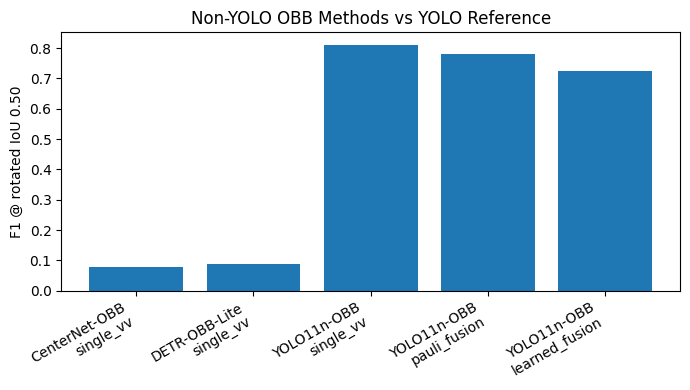

In [14]:
results = pd.DataFrame(
    [
        {"method": "CenterNet-OBB", "framework": "Pure PyTorch", "input": "single_vv", **centernet_metrics},
        {"method": "DETR-OBB-Lite", "framework": "Pure PyTorch", "input": "single_vv", **detr_metrics},
        {"method": "YOLO11n-OBB", "framework": "Ultralytics", "input": "single_vv", "precision": 0.804, "recall": 0.819, "f1": 2 * 0.804 * 0.819 / (0.804 + 0.819), "tp": None, "fp": None, "fn": None},
        {"method": "YOLO11n-OBB", "framework": "Ultralytics", "input": "pauli_fusion", "precision": 0.828, "recall": 0.739, "f1": 2 * 0.828 * 0.739 / (0.828 + 0.739), "tp": None, "fp": None, "fn": None},
        {"method": "YOLO11n-OBB", "framework": "Ultralytics", "input": "learned_fusion", "precision": 0.770, "recall": 0.683, "f1": 2 * 0.770 * 0.683 / (0.770 + 0.683), "tp": None, "fp": None, "fn": None},
    ]
)
display(results)
results.to_csv(OUT_DIR / "non_yolo_vs_yolo_obb_comparison.csv", index=False)

plt.figure(figsize=(7, 4))
plt.bar(results["method"] + "\n" + results["input"], results["f1"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("F1 @ rotated IoU 0.50")
plt.title("Non-YOLO OBB Methods vs YOLO Reference")
plt.tight_layout()
plt.savefig(OUT_DIR / "non_yolo_vs_yolo_f1.png", dpi=160)
plt.show()



## Notes for Guide

- MMRotate was initially considered for Rotated RetinaNet, RoI Transformer,
  Oriented R-CNN, and R3Det.
- Colab Python 3.12 caused dependency failure in `mmcv-full` / older OpenMMLab
  install chain, so that route was avoided for reliable experimentation.
- This notebook instead implements two non-YOLO OBB detectors directly in
  PyTorch:
  - CenterNet-style anchor-free rotated detection.
  - DETR-style transformer query rotated detection.
- This satisfies the requirement to move beyond YOLO while keeping code
  inspectable and simple.
- If stronger SOTA comparison is required later, run MMRotate in a Python 3.10
  local/conda environment rather than Colab Python 3.12.



## Optional SOTA OBB Methods: MMRotate / Python 3.10 Environment

The following four methods are the correct non-YOLO SOTA baselines to compare
against if a Python 3.10 environment is available:

1. Rotated RetinaNet
2. Rotated Faster R-CNN
3. RoI Transformer
4. Oriented R-CNN

They are not run inside the default Colab Python 3.12 kernel because
`mmcv-full`/older OpenMMLab dependencies fail during installation. For a clean
experiment, run them in a local conda environment with Python 3.10 or in a
Colab notebook that launches a separate Python 3.10 environment.

Suggested environment:

```bash
conda create -n mmrotate310 python=3.10 -y
conda activate mmrotate310
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
pip install -U openmim
mim install mmengine mmcv mmdet
pip install git+https://github.com/open-mmlab/mmrotate.git
```



In [15]:
mmrotate_optional_methods = pd.DataFrame(
    [
        {
            "method": "Rotated RetinaNet",
            "family": "one-stage rotated detector",
            "framework": "MMRotate",
            "status": "optional_python310",
            "reason": "Requires mmcv/mmrotate environment; Colab Python 3.12 failed.",
        },
        {
            "method": "Rotated Faster R-CNN",
            "family": "two-stage rotated detector",
            "framework": "MMRotate",
            "status": "optional_python310",
            "reason": "Requires mmcv/mmrotate environment; Colab Python 3.12 failed.",
        },
        {
            "method": "RoI Transformer",
            "family": "two-stage rotated RoI transform detector",
            "framework": "MMRotate",
            "status": "optional_python310",
            "reason": "Requires mmcv/mmrotate environment; Colab Python 3.12 failed.",
        },
        {
            "method": "Oriented R-CNN",
            "family": "oriented proposal-based detector",
            "framework": "MMRotate",
            "status": "optional_python310",
            "reason": "Requires mmcv/mmrotate environment; Colab Python 3.12 failed.",
        },
    ]
)
display(mmrotate_optional_methods)
mmrotate_optional_methods.to_csv(OUT_DIR / "optional_mmrotate_sota_methods.csv", index=False)



,method,family,framework,status,reason
0,Rotated RetinaNet,one-stage rotated detector,MMRotate,optional_python310,Requires mmcv/mmrotate environment; Colab Pyth...
1,Rotated Faster R-CNN,two-stage rotated detector,MMRotate,optional_python310,Requires mmcv/mmrotate environment; Colab Pyth...
2,RoI Transformer,two-stage rotated RoI transform detector,MMRotate,optional_python310,Requires mmcv/mmrotate environment; Colab Pyth...
3,Oriented R-CNN,oriented proposal-based detector,MMRotate,optional_python310,Requires mmcv/mmrotate environment; Colab Pyth...


## Final Detector Study Design

The detector comparison now has two levels:

**Level 1: Runs directly in Colab**

- CenterNet-OBB
- DETR-OBB-Lite
- Previous YOLO11n-OBB reference

**Level 2: SOTA non-YOLO methods for Python 3.10/MMRotate**

- Rotated RetinaNet
- Rotated Faster R-CNN
- RoI Transformer
- Oriented R-CNN

This is the clean way to present it to the guide: we are not ignoring these
methods; we are separating them because their official framework is currently
incompatible with the default Colab environment.
